In [1]:
import pandas as pd
import pathlib as pl
import matplotlib.pyplot as plt

# pain to get working, for some reason
#datDir = pl.Path(r'.~/')
#datDir


# NYC crime
#df = pd.read_csv(datDir / 'New_York_City_Population_by_Borough__1950_-_2040.csv')
# timeColNm = 'Report DateTime'
# df = pd.read_csv(datDir / 'SPD_Crime_Data__2008-Present_20240212.csv',parse_dates=[timeColNm])
# df['year'] = df[timeColNm].dt.year


In [2]:
# Seattle Crime
# https://data.seattle.gov/Public-Safety/SPD-Crime-Data-2008-Present/tazs-3rd5/about_data

timeColNm = 'Report DateTime'
#df = pd.read_csv(datDir / 'SPD_Crime_Data__2008-Present_20240212.csv', parse_dates=[timeColNm])
datDir = pl.Path(r'c:/Users/scott/OneDrive/scotto/projects/politics/data_seattle_crime')
df = pd.read_csv(datDir / 'SPD_Crime_Data__2008-Present_20240212.csv', parse_dates=[timeColNm])
df

,Report Number,Offense ID,Offense Start DateTime,Offense End DateTime,Report DateTime,Group A B,Crime Against Category,Offense Parent Group,Offense,Offense Code,Precinct,Sector,Beat,MCPP,100 Block Address,Longitude,Latitude
0,2020-044620,12605873663,02/05/2020 10:10:00 AM,NaN,2020-02-05 11:24:31,A,SOCIETY,DRUG/NARCOTIC OFFENSES,Drug/Narcotic Violations,35A,W,Q,Q1,MAGNOLIA,32XX BLOCK OF 23RD AVE W,-122.385974,47.649387
1,2020-044452,12605598696,02/03/2020 08:00:00 AM,02/04/2020 08:00:00 AM,2020-02-05 10:06:28,A,PROPERTY,LARCENY-THEFT,Theft of Motor Vehicle Parts or Accessories,23G,N,J,J3,ROOSEVELT/RAVENNA,63XX BLOCK OF 5TH AVE NE,-122.323399,47.675118
2,2020-044465,12605567653,02/02/2020 08:30:00 PM,02/02/2020 09:30:00 PM,2020-02-05 09:39:33,A,PROPERTY,ROBBERY,Robbery,120,N,U,U3,ROOSEVELT/RAVENNA,26TH AVE NE / NE BLAKELEY ST,-122.299552,47.666384
3,2020-044225,12605174036,02/05/2020 01:17:00 AM,02/05/2020 02:21:00 AM,2020-02-05 03:30:55,A,PROPERTY,DESTRUCTION/DAMAGE/VANDALISM OF PROPERTY,Destruction/Damage/Vandalism of Property,290,W,Q,Q1,MAGNOLIA,22XX BLOCK OF W RAYE ST,-122.384865,47.642927
4,2020-044076,12605081469,02/05/2020 12:51:21 AM,NaN,2020-02-05 00:51:31,B,SOCIETY,DRIVING UNDER THE INFLUENCE,Driving Under the Influence,90D,N,B,B2,BALLARD SOUTH,NW 46TH ST / 8TH AVE NW,-122.366195,47.662193
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1103182,2013-247888,7687554356,07/13/2013 01:00:00 AM,NaN,2013-07-13 06:37:00,A,PROPERTY,MOTOR VEHICLE THEFT,Motor Vehicle Theft,240,SW,F,F1,PIGEON POINT,41XX BLOCK OF 20TH AVE SW,-122.359028,47.565702
1103183,2013-227022,7682354808,06/26/2013 11:00:00 AM,06/29/2013 06:30:00 AM,2013-06-29 09:43:00,A,PROPERTY,MOTOR VEHICLE THEFT,Motor Vehicle Theft,240,W,Q,Q3,QUEEN ANNE,1ST AVE N / VALLEY ST,-122.355386,47.626251
1103184,2012-045494,7672915592,02/14/2012 03:04:00 PM,NaN,2012-02-14 15:04:00,A,PROPERTY,LARCENY-THEFT,Shoplifting,23C,N,U,U1,ROOSEVELT/RAVENNA,73XX BLOCK OF ROOSEVELT WAY NE,-122.317464,47.681894
1103185,2010-328592,7692227482,09/19/2010 04:59:00 PM,NaN,2010-09-19 16:59:00,A,PROPERTY,LARCENY-THEFT,Shoplifting,23C,W,M,M3,DOWNTOWN COMMERCIAL,5XX BLOCK OF PIKE ST,-122.335018,47.610909


In [3]:
df['year'] = df[timeColNm].dt.year
murderNm = 'Murder & Nonnegligent Manslaughter'
nMurdersSeattle = df[(df.Offense == murderNm)][['year','Offense']].groupby('year').count()
nMurdersSeattle

,Offense
year,
2008,28
2009,20
2010,16
2011,24
2012,23
2013,18
2014,23
2015,27
2016,20


In [4]:
# from: https://worldpopulationreview.com/us-cities/seattle-wa-population
#popSeattleWRV = pd.read_csv(datDir / 'SeattlePop_WRV.csv')
popSeattleWRV = pd.read_csv('SeattlePop_WRV.csv')
popSeattleWRV['year'] = popSeattleWRV.year.astype(int)


# from: https://www.neilsberg.com/insights/seattle-wa-population-by-year/ (ends in 2022)
#popSeattleNB = pd.read_csv(datDir / 'SeattlePop_Neilsberg.csv')
popSeattleNB = pd.read_csv('SeattlePop_Neilsberg.csv')
popSeattleNB.columns = [s.lower() for s in popSeattleNB.columns]
popSeattleNB = popSeattleNB.iloc[1:-1] # drop bogus 1st and last rows
popSeattleNB['year'] = popSeattleWRV.year.astype(int)
popSeattleNB['population'] = popSeattleNB.population.map(lambda n: int(n.replace(',', '')))

#display(popSeattleNB, popSeattleWRV)

#popSeattle = pd.concat([popSeattleNB, popSeattleWRV.query('year == 2023')])
#popSeattle[['year','population']].dict
popSeattle = dict(popSeattleNB.set_index('year').population)
for ix, df in popSeattleWRV[['year', 'population']].iterrows():
    #print(df)
    popSeattle[df.year] = df.population

popSeattle = pd.Series(popSeattle, name='population')
popSeattle.index.name='year'

In [5]:
popSeattleWRV

,year,population,growth,growthRate
0,1870,1100,0,0.000000
1,1880,3533,2433,2.211818
2,1890,42837,39304,11.124823
3,1900,80671,37834,0.883208
4,1910,237194,156523,1.940264
5,1920,315312,78118,0.329342
6,1930,365583,50271,0.159433
7,1940,368302,2719,0.007437
8,1950,467591,99289,0.269586
9,1960,557087,89496,0.191398


,year,Offense,population,MurderRate
0,2010,16,610654,26.201417
1,2011,24,623130,38.515238
2,2012,23,636557,36.131878
3,2013,18,654300,27.510316
4,2014,23,670896,34.282512
5,2015,27,688247,39.230102
6,2016,20,710687,28.141784
7,2017,27,729644,37.004347
8,2018,32,742889,43.075076
9,2019,32,753291,42.480263


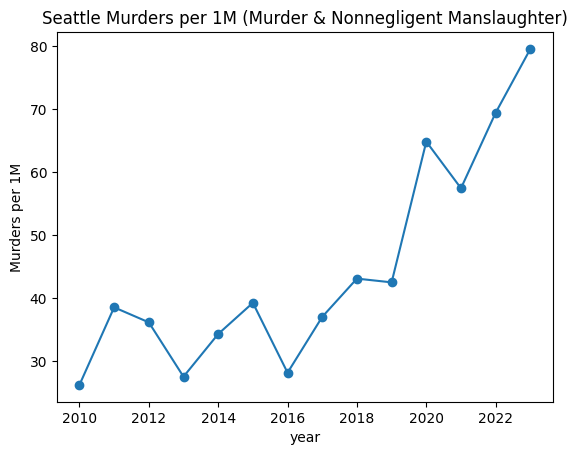

In [6]:
maxYear = 2023 # 2024 not complete yet
murderRate = nMurdersSeattle.reset_index().merge(popSeattle.reset_index(), on='year')
murderRate = murderRate[murderRate.year <= maxYear]
murderRate['MurderRate'] = murderRate.Offense / murderRate.population * 1e6
murderRate.set_index('year').MurderRate.plot(marker='o')

display(murderRate)
plt.ylabel('Murders per 1M')
plt.title(f'Seattle Murders per 1M ({murderNm})');

In [7]:
    

# Select relevant columns
data = data[["Year", "Homicides"]]

# Calculate population for each year
# Replace this with your preferred source for historical Seattle population data
population_url = "https://www.census.gov/quickfacts/fact/table/seattlecitywashington/POP01002020"
population_data = pd.read_html(population_url)[0]
population_data = population_data[["YEAR", "POPULATION"]]
data = pd.merge(data, population_data, on="Year", how="left")

# Calculate murder rate
data["Murder Rate"] = data["Homicides"] / data["POPULATION"] * 100000

# Print or save results
print(data)
#data.to_csv("seattle_homicide_rates.csv", index=False)




NameError: name 'data' is not defined